# Setup

In [1]:
# Base imports
import os
import pickle

# Compute imports
import numpy as np
import pandas as pd
import scipy
from tqdm.notebook import tqdm, trange

# Plotting imports
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
from matplotlib import pyplot as plt
import seaborn as sns
from plotly import express as px

# ML import
from sklearn.decomposition import NMF
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, median_absolute_error, r2_score

In [2]:
DF_GENES_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/cd-hit-results/sim80/Spyo_strain_by_gene.pickle.gz'
DF_GENES_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/panTA-output/gene_presence_absence.Rtab'
CAR_METADATA = '/mnt/craig/pan_phylon/S_pyogenes/metadata/car_metadata.csv'
DF_EGGNOG = '/mnt/craig/pan_phylon/S_pyogenes/processed/df_eggnog.csv'

DF_CORE_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_core.pickle'
DF_CORE_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_core_panta_cdhit.pickle'
DF_ACC_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_acc.pickle'
DF_ACC_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_acc_panta_cdhit.pickle'
DF_RARE_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_rare.pickle'
DF_RARE_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_rare_panta_cdhit.pickle'

L_MATRIX_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/L_norm.csv'
A_MATRIX_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/A_norm.csv'

L_BIN_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/L_binarized.csv'
A_BIN_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/A_binarized.csv'

In [3]:
# Load in (full) P matrix
df_genes_cdhit = pd.read_pickle(DF_GENES_CDHIT)
DF_GENES_PANTA_CDHIT = pd.read_csv(DF_GENES_PANTA_CDHIT, sep='\t', index_col='Gene')

# Load in (full) metadata
metadata = pd.read_csv(CAR_METADATA, index_col=0, dtype='object')
#metadata = metadata[metadata.genome_status == 'Complete']

# Load in eggNOG gene annotations
#df_eggnog = pd.read_csv(DF_EGGNOG, index_col=0, dtype='object')

In [4]:
df_core_cdhit = pd.read_pickle(DF_CORE_CDHIT)
df_acc_cdhit = pd.read_pickle(DF_ACC_CDHIT)
df_rare_cdhit = pd.read_pickle(DF_RARE_CDHIT)

df_core_panta_cdhit = pd.read_pickle(DF_CORE_PANTA_CDHIT)
df_acc_panta_cdhit = pd.read_pickle(DF_ACC_PANTA_CDHIT)
df_rare_panta_cdhit = pd.read_pickle(DF_RARE_PANTA_CDHIT)

display(
    df_acc_cdhit.shape,
    df_acc_panta_cdhit.shape
)

(1071, 399)

(1167, 399)

In [5]:
# Characterize pangenome

L_norm_panta_cdhit = pd.read_csv(L_MATRIX_PANTA_CDHIT, index_col=0)
A_norm_panta_cdhit = pd.read_csv(A_MATRIX_PANTA_CDHIT, index_col=0)

display(
    L_norm_panta_cdhit.shape,
    L_norm_panta_cdhit.head(),
    A_norm_panta_cdhit.shape,
    A_norm_panta_cdhit.head()
)

(1167, 11)

,0,1,2,3,4,5,6,7,8,9,10
Gene,,,,,,,,,,,
lcnDR2,0.712812,0.939065,0.939843,0.000000,0.205742,0.902570,0.907122,0.000000,0.252395,0.000000,0.057409
groups_827,0.090928,0.053527,0.000000,0.000000,0.000000,0.000000,0.037116,0.057578,0.000000,0.449195,0.025756
groups_2624,0.091840,1.000978,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.033232,0.006369
groups_2534,0.000000,0.888956,0.109518,0.000000,0.962850,1.000082,0.789291,0.000000,0.000000,0.000000,0.000000
groups_3444,0.063994,0.996370,0.000000,0.928485,0.000000,0.075066,0.013602,0.945660,0.000000,0.000000,0.000000


(11, 399)

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
0,0.398036,0.032514,0.000000,0.000000,0.000000,0.520651,0.298003,0.141858,0.120537,0.000000,...,0.0,0.069586,0.0,0.000000,0.026241,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,1.010850,0.000000,0.000000,0.038682,0.000000,0.000000,...,0.0,0.032786,0.0,0.000000,0.005310,0.000000,0.970819,0.000000,0.074132,0.000000
2,0.007992,0.027134,0.000000,0.000000,0.000000,0.132190,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.042623,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.114473,0.000000,0.000000,0.023177,0.016332,...,0.0,0.000000,0.0,1.019188,0.000000,0.000000,0.000000,0.022634,0.000000,0.000000
4,0.000000,0.000000,1.271563,1.270103,0.011674,0.105740,0.000000,0.054936,0.183404,0.000000,...,0.0,0.008513,0.0,0.029932,0.000000,0.976348,0.000000,0.000000,0.297325,1.270652


In [6]:
L_binarized_panta_cdhit = pd.read_csv(L_BIN_PANTA_CDHIT, index_col=0)
A_binarized_panta_cdhit = pd.read_csv(A_BIN_PANTA_CDHIT, index_col=0)

display(
    L_binarized_panta_cdhit.shape,
    L_binarized_panta_cdhit.head(),
    A_binarized_panta_cdhit.shape,
    A_binarized_panta_cdhit.head()
)

(1167, 11)

,0,1,2,3,4,5,6,7,8,9,10
Gene,,,,,,,,,,,
lcnDR2,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
groups_827,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_2624,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_2534,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
groups_3444,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


(11, 399)

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


# Characterize phylons by strain affinity (`A_binarized`)

In [7]:
L_norm_panta_cdhit.columns = [f'phylon{i}' for i in L_norm_panta_cdhit.columns]
L_binarized_panta_cdhit.columns = [f'phylon{i}' for i in L_binarized_panta_cdhit.columns]

display(
    L_norm_panta_cdhit.head(),
    L_binarized_panta_cdhit.head()
)

,phylon0,phylon1,phylon2,phylon3,phylon4,phylon5,phylon6,phylon7,phylon8,phylon9,phylon10
Gene,,,,,,,,,,,
lcnDR2,0.712812,0.939065,0.939843,0.000000,0.205742,0.902570,0.907122,0.000000,0.252395,0.000000,0.057409
groups_827,0.090928,0.053527,0.000000,0.000000,0.000000,0.000000,0.037116,0.057578,0.000000,0.449195,0.025756
groups_2624,0.091840,1.000978,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.033232,0.006369
groups_2534,0.000000,0.888956,0.109518,0.000000,0.962850,1.000082,0.789291,0.000000,0.000000,0.000000,0.000000
groups_3444,0.063994,0.996370,0.000000,0.928485,0.000000,0.075066,0.013602,0.945660,0.000000,0.000000,0.000000


,phylon0,phylon1,phylon2,phylon3,phylon4,phylon5,phylon6,phylon7,phylon8,phylon9,phylon10
Gene,,,,,,,,,,,
lcnDR2,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
groups_827,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_2624,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_2534,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
groups_3444,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [8]:
A_norm_panta_cdhit.index = [f'phylon{i}' for i in A_norm_panta_cdhit.index]
A_binarized_panta_cdhit.index = [f'phylon{i}' for i in A_binarized_panta_cdhit.index]

display(
    A_norm_panta_cdhit.head(),
    A_binarized_panta_cdhit.head()
)

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
phylon0,0.398036,0.032514,0.000000,0.000000,0.000000,0.520651,0.298003,0.141858,0.120537,0.000000,...,0.0,0.069586,0.0,0.000000,0.026241,0.000000,0.000000,0.000000,0.000000,0.000000
phylon1,0.000000,0.000000,0.000000,0.000000,1.010850,0.000000,0.000000,0.038682,0.000000,0.000000,...,0.0,0.032786,0.0,0.000000,0.005310,0.000000,0.970819,0.000000,0.074132,0.000000
phylon2,0.007992,0.027134,0.000000,0.000000,0.000000,0.132190,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.042623,0.000000
phylon3,0.000000,0.000000,0.000000,0.000000,0.000000,0.114473,0.000000,0.000000,0.023177,0.016332,...,0.0,0.000000,0.0,1.019188,0.000000,0.000000,0.000000,0.022634,0.000000,0.000000
phylon4,0.000000,0.000000,1.271563,1.270103,0.011674,0.105740,0.000000,0.054936,0.183404,0.000000,...,0.0,0.008513,0.0,0.029932,0.000000,0.976348,0.000000,0.000000,0.297325,1.270652


,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
phylon0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
phylon2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


## Plotting strain affinities for each phylon

In [9]:
def get_current_thresholds(A_norm, A_binarized):
    phylon_thresholds = dict.fromkeys(A_norm_panta_cdhit.index)
    
    for phylon in A_norm_panta_cdhit.index:
        bin_vec = A_binarized_panta_cdhit.loc[phylon]
        bin_strains = bin_vec[bin_vec==1].index
        threshold = A_norm_panta_cdhit.loc[phylon, bin_strains].min()
        phylon_thresholds[phylon] = threshold
        
    return phylon_thresholds


In [10]:
# Binarization thresholds for phylon affinity matrix A (phylons x strains)
# These are the default thresholds (calculated from k-means,k=3)
# We will override them as necessary based on the histogram below

phylon_thresholds = get_current_thresholds(A_norm_panta_cdhit, A_binarized_panta_cdhit)
phylon_thresholds

{'phylon0': np.float64(0.6196625618204031),
 'phylon1': np.float64(0.951106811522284),
 'phylon2': np.float64(0.9259361956983796),
 'phylon3': np.float64(0.9908913575307084),
 'phylon4': np.float64(0.6899372849238345),
 'phylon5': np.float64(0.7434350199606885),
 'phylon6': np.float64(0.8067494568713043),
 'phylon7': np.float64(0.7729759165176954),
 'phylon8': np.float64(0.5806429236661533),
 'phylon9': np.float64(0.826466750252661),
 'phylon10': np.float64(0.8990417973057899)}

__START: REPEAT THE FOLLOWING SET OF CELLS UNTIL ALL PHYLONS ARE CHARACTERIZED AND THRESHOLDS ARE SET__

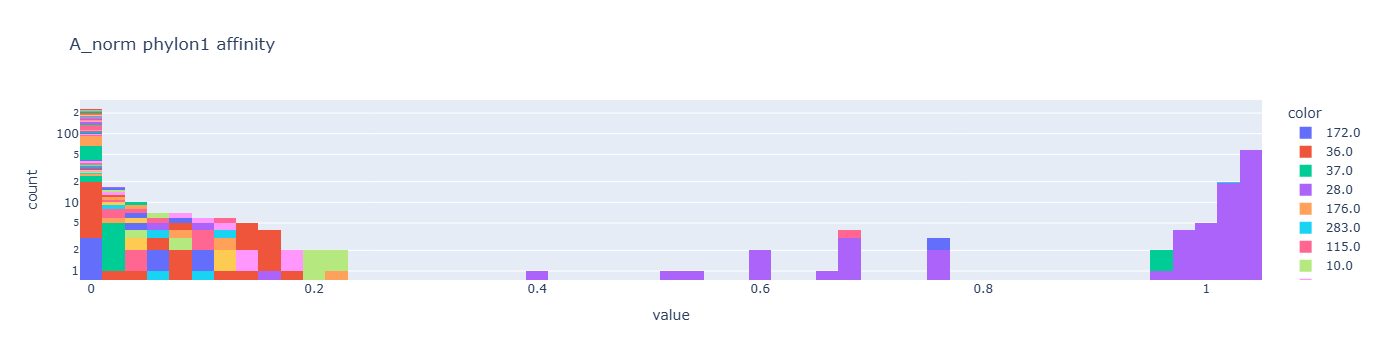

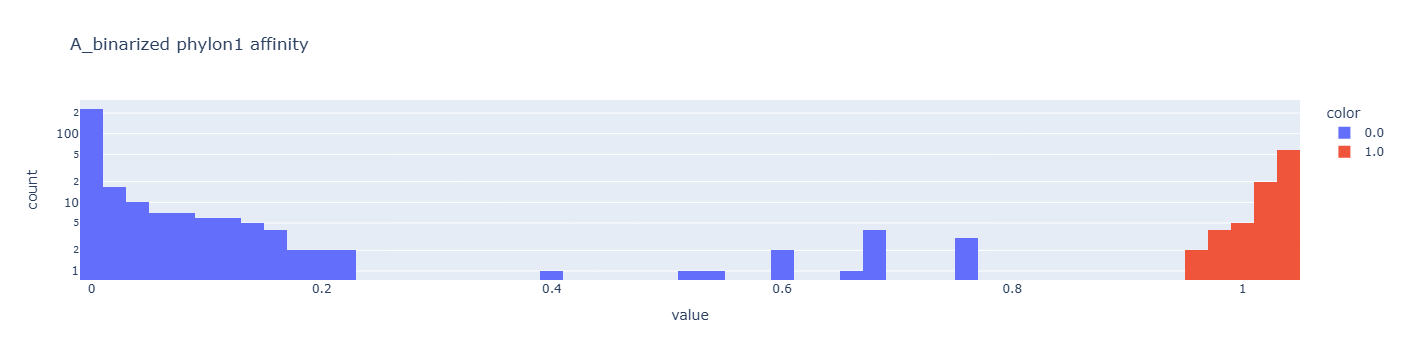

In [11]:
i = 1 # change this for each phylon until you've characterized them all

fig1 = px.histogram(A_norm_panta_cdhit.loc[f'phylon{i}'], color=metadata.mlst.astype(float), log_y=True, title=f'A_norm phylon{i} affinity', nbins=100)
fig2 = px.histogram(A_norm_panta_cdhit.loc[f'phylon{i}'], color=A_binarized_panta_cdhit.loc[f'phylon{i}'], log_y=True, title=f'A_binarized phylon{i} affinity', nbins=100)

fig1.show()
fig2.show()

## High affinity strains

In [12]:
# Number of genes in phylon (if its low e.g. < 100, then the phylon is likely a mobilome / auxiliary phylon
(L_binarized_panta_cdhit[f'phylon{i}'] == 1).sum()

np.int64(446)

### Use default threshold (K-means, k=3) or a custom threshold based on the distribution above

In [13]:
curr_threshold = phylon_thresholds[f'phylon{i}']
curr_threshold

np.float64(0.951106811522284)

In [14]:
high_affinity = A_norm_panta_cdhit.loc[f'phylon{i}'] >= curr_threshold
high_affinity_strains = A_norm_panta_cdhit.loc[f'phylon{i}'][high_affinity].index

# You can add in species classification here too
display(
    metadata.set_index('genome_id').loc[high_affinity_strains].mlst.value_counts(),
    metadata.set_index('genome_id').loc[high_affinity_strains].bioproject_accession.value_counts(),
    metadata.set_index('genome_id').loc[high_affinity_strains].isolation_source.value_counts()
)

mlst
28     87
-1      1
785     1
Name: count, dtype: int64

bioproject_accession
PRJNA1076228    59
PRJNA1070447     7
PRJNA656382      4
PRJNA1050251     4
PRJEB29800       2
PRJNA175952      1
PRJNA454341      1
PRJNA289181      1
PRJNA252999      1
PRJNA684347      1
PRJNA657283      1
PRJNA1025265     1
PRJNA13888       1
PRJNA1082515     1
PRJDB141         1
PRJNA1087113     1
PRJNA1357344     1
PRJEB27939       1
Name: count, dtype: int64

isolation_source
not provided                        55
throat                               5
blood                                4
Necrotizing fasciitis patient        1
Tissue                               1
Venous                               1
invasive case                        1
plevra                               1
blood from 65-years-old female       1
Pus from 39-years-old male           1
blood from 77-years-old female       1
Genital from 59-years-old female     1
blood from 71-years-old female       1
wound from 6-years-old male          1
blood from 54-years-old male         1
throat swab                          1
Blood culture                        1
Name: count, dtype: int64

## Max affinity strain

In [15]:
max_affinity_strain = metadata.set_index('genome_id').loc[[A_norm_panta_cdhit.loc[f'phylon{i}'].idxmax()]] # max affinity strain
cols = [
    'genome_name',
    'mlst',
    'publication',
    'bioproject_accession',
    'biosample_accession',
    'assembly_accession',
    'sequencing_depth',
    'contigs',
    'genome_length',
    'isolation_source',
    'country_merged'
]
    
    

metadata.set_index('genome_id').loc[max_affinity_strain.index[0], cols]

genome_name                      NaN
mlst                              28
publication                      NaN
bioproject_accession    PRJNA1076228
biosample_accession     SAMN39934777
assembly_accession               NaN
sequencing_depth                 NaN
contigs                            1
genome_length                1838853
isolation_source        not provided
country_merged               Iceland
Name: GCF_051530335.1, dtype: object

In [16]:
phylon_thresholds[f'phylon{i}'] = curr_threshold # sets binarization threshold based on your choice above
phylon_thresholds

{'phylon0': np.float64(0.6196625618204031),
 'phylon1': np.float64(0.951106811522284),
 'phylon2': np.float64(0.9259361956983796),
 'phylon3': np.float64(0.9908913575307084),
 'phylon4': np.float64(0.6899372849238345),
 'phylon5': np.float64(0.7434350199606885),
 'phylon6': np.float64(0.8067494568713043),
 'phylon7': np.float64(0.7729759165176954),
 'phylon8': np.float64(0.5806429236661533),
 'phylon9': np.float64(0.826466750252661),
 'phylon10': np.float64(0.8990417973057899)}

__END: REPEAT THIS SET OF CELLS UNTIL ALL PHYLONS ARE CHARACTERIZED AND THRESHOLDS ARE SET__

If you have a name for your phylon, add it below to `phylon_mapping`

## Thresholds for characterized A_bin

In [17]:
# # Custom thresholds entered here
# phylon_thresholds['phylon2'] = 0.7
# phylon_thresholds['phylon21'] = 0.7
# phylon_thresholds['phylon22'] = 0.66

In [18]:
char_A_bin = A_norm_panta_cdhit.astype(bool).copy(deep=True)

for phylon in A_norm_panta_cdhit.index:
    char_A_bin.loc[phylon] = A_norm_panta_cdhit.loc[phylon] > phylon_thresholds[phylon]

char_A_bin = char_A_bin.astype(int)

A_binarized_panta_cdhit = char_A_bin.astype(float)
A_binarized_panta_cdhit

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
phylon0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
phylon2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
phylon5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phylon8,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
phylon9,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## Mapping

In [19]:
# Change the names of the phylons once you have characterized them
# If you cannot find an initial characterization, label it "unchar-x"
# where x is the number

phylon_mapping = {
    'phylon0': 'emm-patternE-other', # 81% purity, generalist (Mga, Mrp, SfbI)
    'phylon1': 'ST28-emm1', # A-C3 (99%)
    'phylon2': 'ST52-emm28', # E4 (100%)
    'phylon3': 'ST39-emm4', # E1 (93%)
    'phylon4': 'emm3/6/5', # A-C3 (37.5%), Y aka ungrouped D/E types (40%)
    'phylon5': 'ST36', # E4 (100%), emm12 = 72% + emm82 = 24%
    'phylon6': 'ST63-emm77', # E4 (100%)
    'phylon7': 'SpeK-prophage',
    'phylon8': 'emm-patternD-other', # 92% purity (D only = 63%, Y aka ungrouped D/E types = 29%), skin specialists (Nra, Enn, SfbII)
    'phylon9': 'SpeC-prophage',
    'phylon10': 'ST101-emm89', # E4 (100%)
}


In [20]:
metadata

,genome_id,source,genome_name,organism_name,taxon_id,strain,# ambiguous bases,# genomes,0,1,...,mash_cluster_initial,mash_cluster_filtered,iso_raw,host_cat,source_cat,country_merged,Num of emm-clusters,Predicted emm-type,Possible emm-like alleles,emm cluster
0,1010840.4,BV-BRC,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,MGAS1882,NaN,NaN,NaN,NaN,...,89,NaN,NaN,Not Specified,Not Specified,USA,2,emm_59.0,_emm_174.1*,E6
1,1048264.3,BV-BRC,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,HKU QMH11M0907901,NaN,NaN,NaN,NaN,...,6,NaN,blood from scarlet fever outbreak,Human,Blood,China,1,emm_12.0,NaN,A-C4
2,1150773.3,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,7,8.0,NaN,Not Specified,Not Specified,NaN,1,emm_6.52,NaN,Single protein cluster clade Y
3,1150773.4,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,7,8.0,NaN,Not Specified,Not Specified,NaN,1,emm_6.52,NaN,Single protein cluster clade Y
4,1235829.3,BV-BRC,Streptococcus pyogenes A20,Streptococcus pyogenes A20,1235829,A20,NaN,NaN,NaN,NaN,...,2,2.0,necrotizing fasciitis patient,Human,Soft Tissue,Taiwan,1,emm_1.0,NaN,A-C3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394,GCF_055378755.1,NCBI,NaN,Streptococcus pyogenes,1314,D58,0.0,30.0,2.0,674.0,...,16,6.0,NaN,Not Specified,Not Specified,USA,1,emm_3.0,NaN,A-C5
395,GCF_900608505.1,NCBI,NaN,Streptococcus pyogenes,1314,S119,0.0,240.0,1.0,523.0,...,2,2.0,blood culture,Human,Blood,France,1,emm_1.0,NaN,A-C3
396,GCF_900636425.1,NCBI,NaN,Streptococcus pyogenes,1314,NCTC12060,0.0,30.0,4.0,672.0,...,27,NaN,not available: to be reported later,Not Specified,Not Specified,United Kingdom,3,emm_80.0,_emm_156.1~*;_emm_138.1~*,D4
397,GCF_900636485.1,NCBI,NaN,Streptococcus pyogenes,1314,NCTC8232,0.0,30.0,2.0,673.0,...,12,NaN,not available: to be reported later,Not Specified,Not Specified,United Kingdom,1,emm_47.1,NaN,Single protein cluster clade Y


In [21]:
L_norm_panta_cdhit.rename(mapper=phylon_mapping, axis=1, inplace=True)
L_binarized_panta_cdhit.rename(mapper=phylon_mapping, axis=1, inplace=True)
A_norm_panta_cdhit.rename(mapper=phylon_mapping, axis=0, inplace=True)
A_binarized_panta_cdhit.rename(mapper=phylon_mapping, axis=0, inplace=True)

# Plot `L_norm` & `L_binarized` matrices

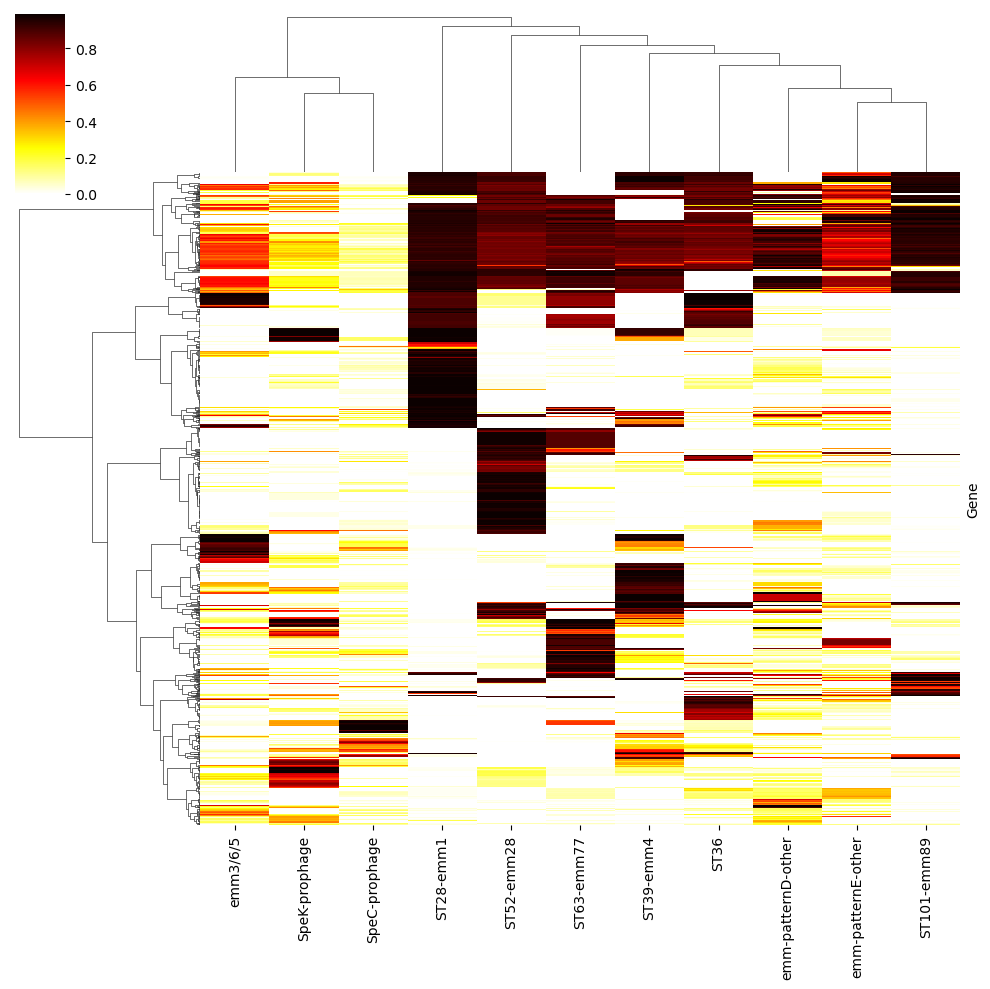

In [22]:
# Plot renamed L_norm clustermap
g = sns.clustermap(L_norm_panta_cdhit,
                   method='ward',
                   cmap='hot_r',
                   yticklabels=False,
                   robust=True,
                  )

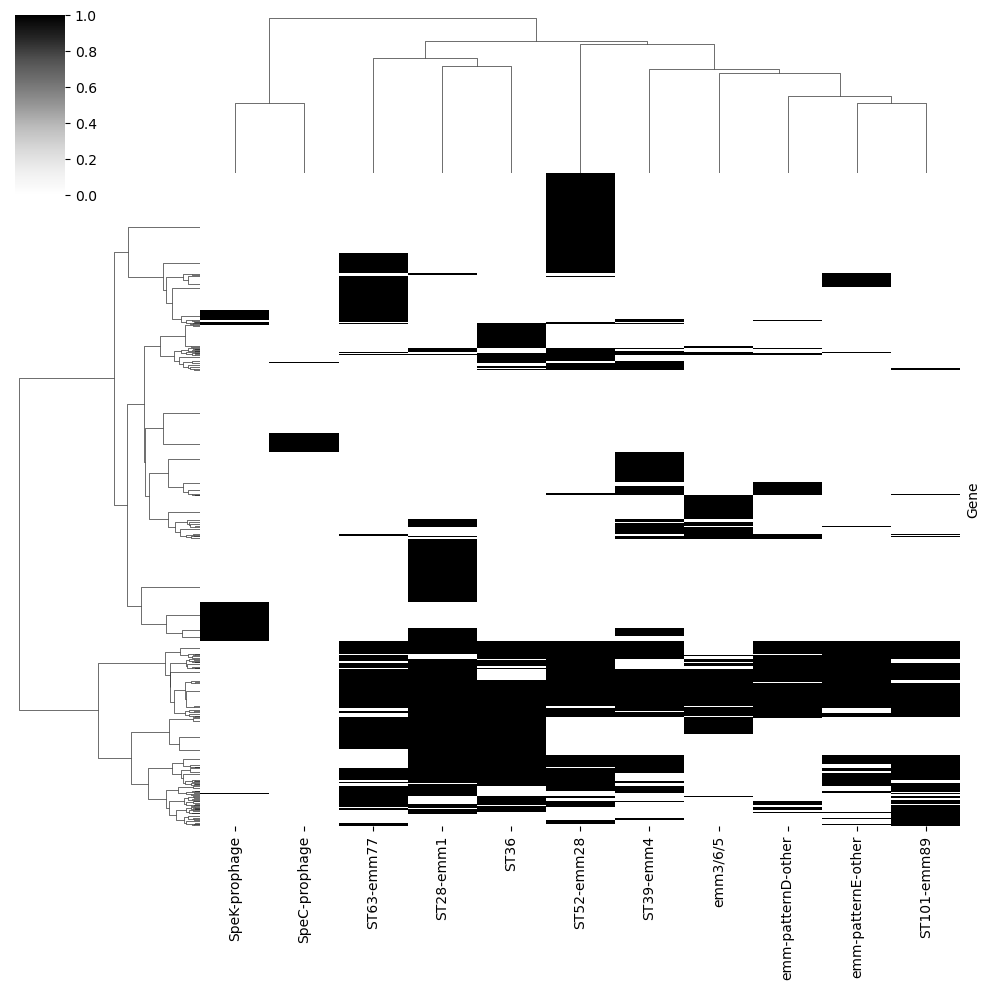

In [23]:
# Plot renamed L_binarized clustermap
g_bin = sns.clustermap(L_binarized_panta_cdhit,
                       method='ward',
                       metric='euclidean', # metric must be euclidean for ward (even if binarized)
                       cmap='Greys',
                       yticklabels=False,
                       robust=True
                      )

# Save order of phylons
phylon_order = g_bin.data2d.columns

## Gene frequency vs # of active phylons

<Axes: ylabel='Count'>

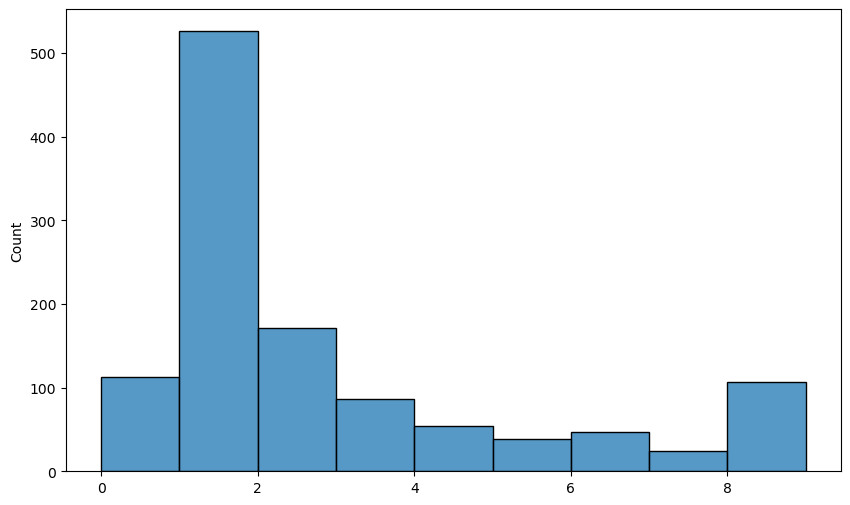

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(L_binarized_panta_cdhit.sum(axis=1), ax=ax, binwidth=1)

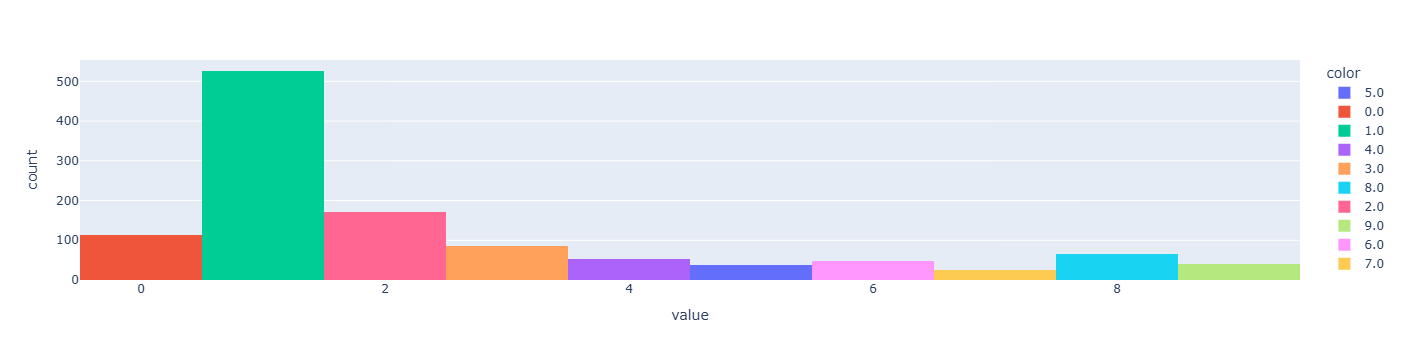

In [25]:
px.histogram(L_binarized_panta_cdhit.sum(axis=1), color=L_binarized_panta_cdhit.sum(axis=1))

# 330 (19%) genes in 0 phylons
# 0 (0%) genes in 18 phylons (all phylons minus mge-modes)
# 442 genes (26%) in only 1 phylon (genes with most differentiating power)
# 244 genes (14%) in 2 phylons
# 148 genes (9%) in 3 phylons
# 109 genes (6%) in 4 phylons
# 76 genes (4%) in 5 phylons

In [26]:
pd.DataFrame(L_binarized_panta_cdhit.sum(axis=1).value_counts()).sort_index().cumsum() # Cum sum

,count
0.0,113
1.0,639
2.0,810
3.0,896
4.0,950
5.0,989
6.0,1036
7.0,1060
8.0,1126
9.0,1167


<Axes: >

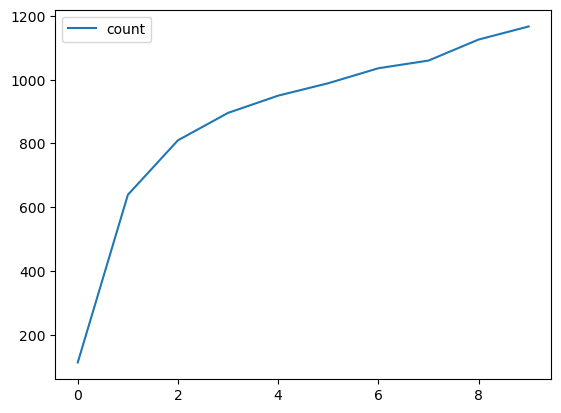

In [27]:
# Cum sum line plot
sns.lineplot(pd.DataFrame(L_binarized_panta_cdhit.sum(axis=1).value_counts()).sort_index().cumsum())

Line of best fit: y=[0.02152429]*x + -0.320408325439308
R2 score: 0.9146383402954386


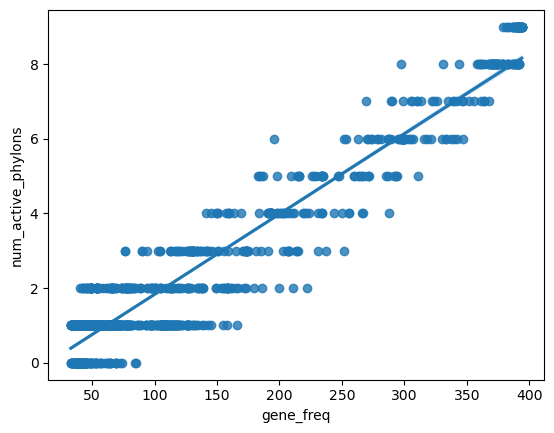

In [28]:
df_gene_freq_by_phylon = pd.DataFrame(index=L_binarized_panta_cdhit.index)

df_gene_freq_by_phylon['num_active_phylons'] = L_binarized_panta_cdhit.sum(axis=1)
df_gene_freq_by_phylon['gene_freq'] = DF_GENES_PANTA_CDHIT.loc[L_binarized_panta_cdhit.index].sum(axis=1)
#df_gene_freq_by_phylon['gene_freq'] = df_gene_freq_by_phylon['gene_freq'].sparse.to_dense()

# Create a Linear Regression model
model = LinearRegression()

# Fit the model
X = df_gene_freq_by_phylon['gene_freq'].values.reshape(-1,1)
y = df_gene_freq_by_phylon['num_active_phylons'].values
model.fit(X, y)

# Predict the y-values
y_pred = model.predict(X)

# Extract coefficients (slope) and intercept from the model
slope = model.coef_
intercept = model.intercept_

# Calculate R^2 value
r2 = r2_score(y, y_pred)

# Display results
print(f'Line of best fit: y={slope}*x + {intercept}')
print(f'R2 score: {r2}')

ax = sns.regplot(df_gene_freq_by_phylon, x='gene_freq', y='num_active_phylons')
plt.show()

# Plot `L_binarized` with sorted genes & phylons

In [29]:
gene_order = []

# # Add in zero-phylon genes
# zero_cond = L_binarized_panta_cdhit.sum(axis=1) == 0
# gene_order.extend(L_binarized_panta_cdhit[zero_cond].index)

# Add in single-phylon genes
for phylon in phylon_order:
    single_cond = L_binarized_panta_cdhit.sum(axis=1) == 1
    inPhylon = L_binarized_panta_cdhit[phylon] == 1
    gene_order.extend(L_binarized_panta_cdhit[inPhylon & single_cond].index)

# Add in poly-phylon genes
for num_active_phylons in trange(2, int(L_binarized_panta_cdhit.sum(axis=1).max())+1):
    num_cond = L_binarized_panta_cdhit.sum(axis=1) == num_active_phylons
    gg = sns.clustermap(L_binarized_panta_cdhit[num_cond], method='ward', metric='euclidean', col_cluster=False, yticklabels=False);
    plt.close();
    gene_order.extend(gg.data2d.index)

  0%|          | 0/8 [00:00<?, ?it/s]

/opt/miniconda3/envs/jupyterlab/lib/python3.12/site-packages/seaborn/matrix.py:615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(0, max_dependent_coord * 1.05)


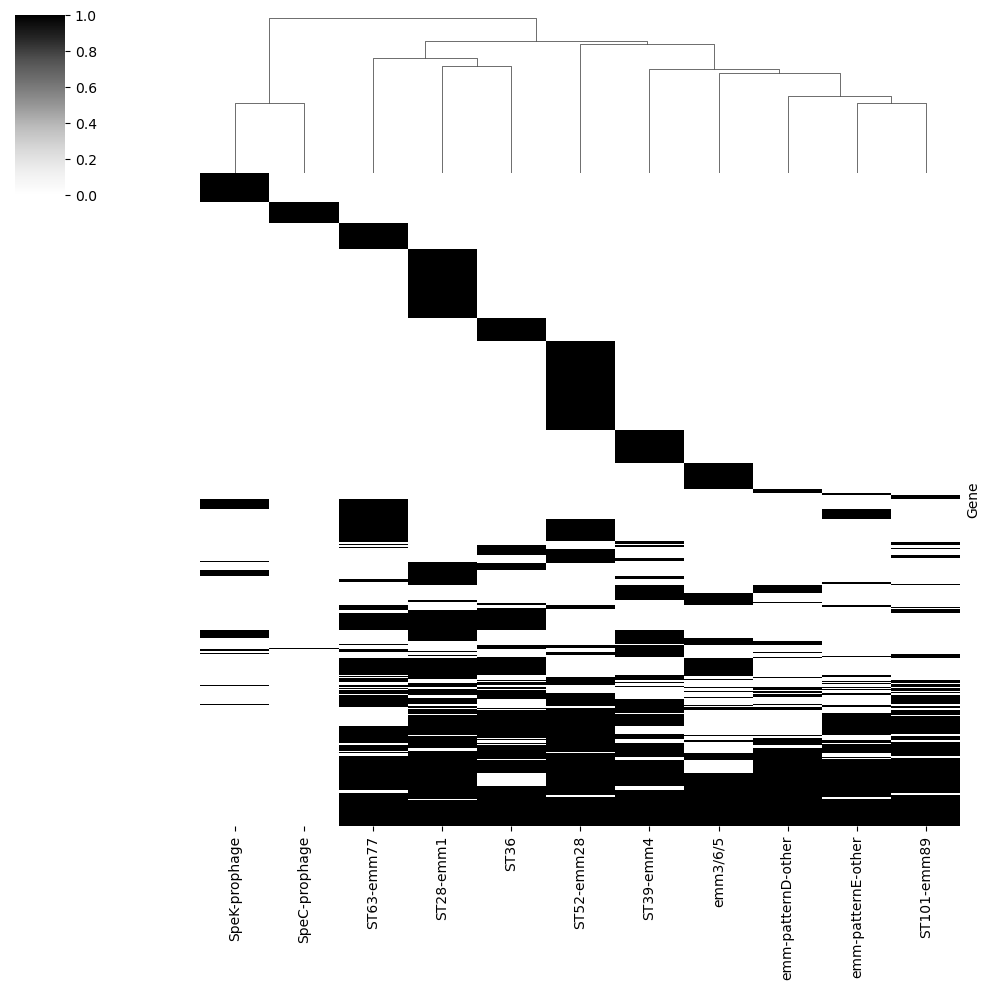

In [30]:
# Main sorted clustermap

g = sns.clustermap(
    L_binarized_panta_cdhit.loc[gene_order],
    method='ward',
    metric='euclidean',
    row_cluster=False,
    yticklabels=False,
    cmap='Greys'
)

In [31]:
g.savefig("L_bin_sorted_panta_cdhit.pdf", dpi=300, bbox_inches="tight", transparent=True)

In [32]:
g.savefig("L_bin_sorted_panta_cdhit.png", dpi=300, bbox_inches="tight", transparent=True)

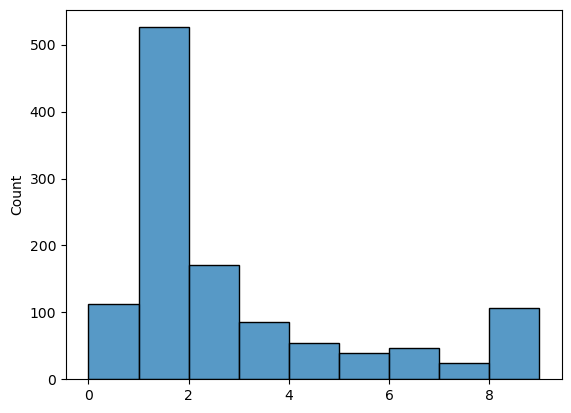

In [33]:
# Histogram of genes in L_binarized by num of phylons they are active in
fig, ax = plt.subplots()
sns.histplot(L_binarized_panta_cdhit.sum(axis=1), binwidth=1, ax=ax)
plt.show()

In [34]:
fig.savefig('Histogram_L_bin_panta_cdhit_num_phylons.pdf', transparent=True)

# Plot sorted, corresponding A_binarized matrix

In [35]:
strain_order = []
unchar_strain_order = []


# zero-phylon strains
noPhylon = A_binarized_panta_cdhit.sum() == 0
strain_order.extend(A_binarized_panta_cdhit.sum()[noPhylon].index.tolist())

# strain lists
single_phylon_strains = A_binarized_panta_cdhit.sum()[A_binarized_panta_cdhit.sum() == 1].index # 715 (30%)
multi_phylon_strains = A_binarized_panta_cdhit.sum()[A_binarized_panta_cdhit.sum() > 1].index # 1596 (67%)

for phylon in phylon_order:
    if '-DAEC' in phylon:
        continue
    elif 'MGE' in phylon:
        continue
    elif '-aux' in phylon:
        continue
    elif '-ShigaToxin' in phylon:
        continue
    elif 'cassette' in phylon:
        continue
    elif 'bactin' in phylon:
        continue
    elif 'island' in phylon:
        continue
    elif 'Flagella' in phylon:
        continue
    elif 'phage' in phylon:
        continue
    elif 'plasmid' in phylon:
        continue
    elif 'O16:H5' in phylon:
        continue
    elif 'O25:H4' in phylon:
        continue
    else:
        phylon_aff_binarized_single = A_binarized_panta_cdhit.loc[phylon, single_phylon_strains]
        phylon_aff_binarized_multi = A_binarized_panta_cdhit.loc[phylon, multi_phylon_strains]
    
        inPhylon_single = phylon_aff_binarized_single == 1
        inPhylon_multi = phylon_aff_binarized_multi == 1
    
        list1 = phylon_aff_binarized_single[inPhylon_single].index.tolist()
        list2 = phylon_aff_binarized_multi[inPhylon_multi].index.tolist()
        new_list2 = list(set(list2) - set(strain_order)) # ensures no double-counting
        
        strain_order.extend(list1)
        strain_order.extend(new_list2)

for phylon in phylon_order: # must be done after the first loop
    if 'unchar' in phylon or 'mge' in phylon or '-aux' in phylon:
        phylon_aff_binarized_single = A_binarized_panta_cdhit.loc[phylon, single_phylon_strains]
        phylon_aff_binarized_multi = A_binarized_panta_cdhit.loc[phylon, multi_phylon_strains]
    
        inPhylon_single = phylon_aff_binarized_single == 1
        inPhylon_multi = phylon_aff_binarized_multi == 1
    
        list1 = phylon_aff_binarized_single[inPhylon_single].index.tolist()
        list2 = phylon_aff_binarized_multi[inPhylon_multi].index.tolist()
        new_list1 = list(set(list1) - set(strain_order)) # ensures no double-counting
        new_list2 = list(set(list2) - set(strain_order)) # ensures no double-counting
        
        strain_order.extend(new_list1)
        strain_order.extend(new_list2)

strain_order += unchar_strain_order

len(strain_order)

394

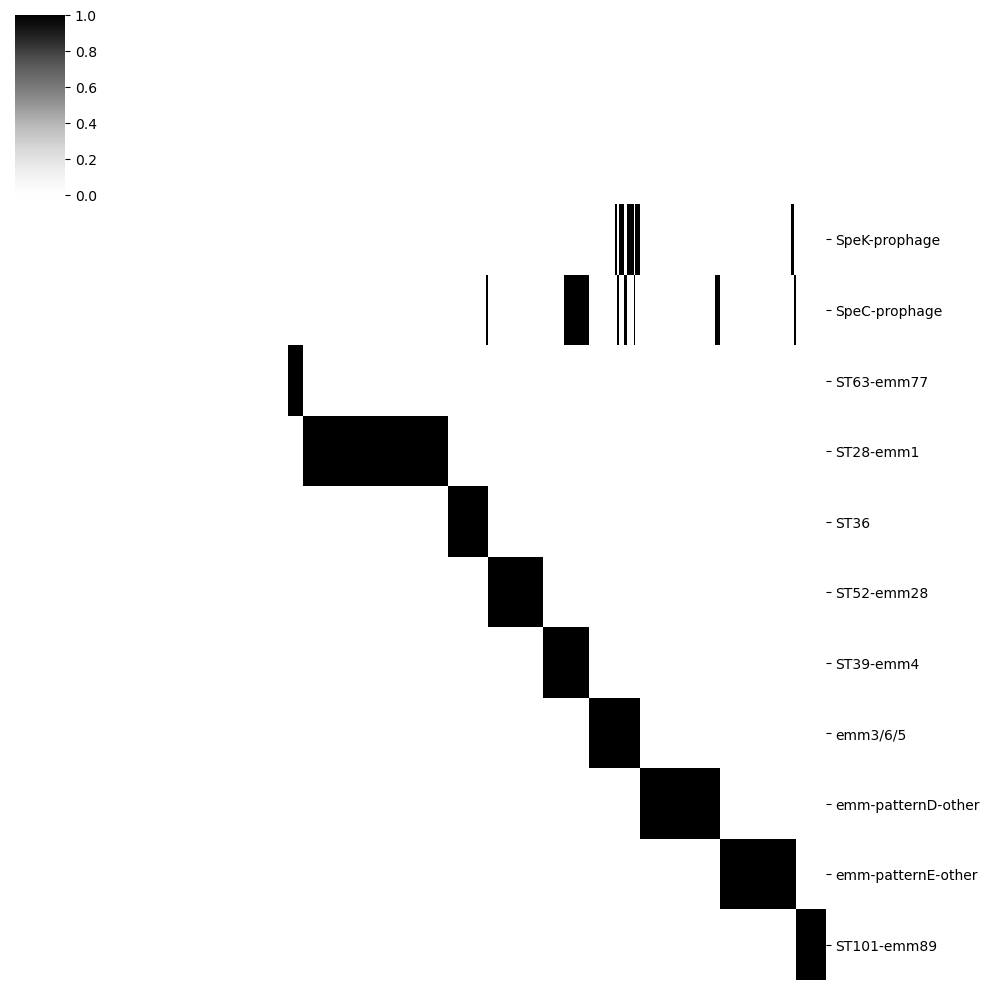

In [36]:
# A-binarized
sns.clustermap(A_binarized_panta_cdhit.loc[phylon_order, strain_order], cmap='Greys', xticklabels=False, row_cluster=False, col_cluster=False)

In [37]:
characterized = list(phylon_order.copy(deep=True))

characterized.remove('SpeK-prophage')
characterized.remove('SpeC-prophage')

characterized

['ST63-emm77',
 'ST28-emm1',
 'ST36',
 'ST52-emm28',
 'ST39-emm4',
 'emm3/6/5',
 'emm-patternD-other',
 'emm-patternE-other',
 'ST101-emm89']

In [38]:
custom_colors = [
    # Shades of red/orange/yellow
    "White",
    "IndianRed",
    "DarkRed",
    "FireBrick",
    "Tomato",
    "Gold",
    "DarkGoldenrod",
    "Goldenrod",
    # Other species
    "Green",
    "Blue",
    "Purple",
    "Cyan",
    "Magenta",
    "Lime",
    "Pink",
    "Grey",
    "Plum",
    "MediumSeaGreen",
    "Teal",
    "CornflowerBlue",
    "DarkSalmon",
    "SteelBlue",
    "Turquoise",
    "HotPink"
]

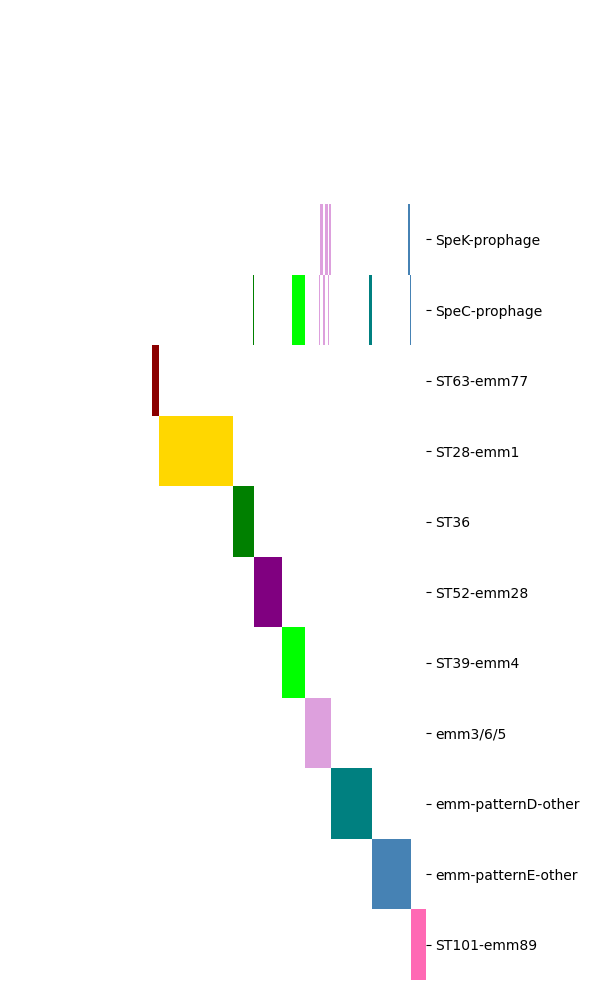

In [39]:
A_bin_plotting = A_binarized_panta_cdhit.loc[phylon_order, strain_order]
for strain in A_bin_plotting.columns:
    if A_bin_plotting.loc[characterized, strain].max() > 0:
        phylon = A_bin_plotting.loc[characterized, strain].idxmax()
        mult = characterized.index(phylon) + 1
        A_bin_plotting[strain] *= mult

# A-binarized
g = sns.clustermap(A_bin_plotting.loc[phylon_order, strain_order].astype(int), xticklabels=False, row_cluster=False, col_cluster=False,
               cmap = custom_colors, figsize=(6,10), cbar_pos=None)

fig = plt.gcf()
plt.show()

In [40]:
g.data2d.columns

Index(['1010840.4', '1314.1007', '1314.1011', '1314.1016', '1314.1021',
       '1314.1048', '1314.197', '1314.213', '1314.214', '1314.2403',
       ...
       'GCF_041430935.1', 'GCF_041430955.1', 'GCF_041431015.1',
       'GCF_041431055.1', 'GCF_055361705.1', 'GCF_055361715.1',
       'GCF_055361825.1', 'GCF_055361865.1', 'GCF_055362005.1',
       'GCF_055362085.1'],
      dtype='str', length=394)

In [41]:
fig.savefig('A_char_colored.png', dpi=600, transparent=True)

In [42]:
len(strain_order)

394

In [43]:
cond = L_binarized_panta_cdhit.sum(axis=1) == 1

L_binarized_panta_cdhit[cond]

,emm-patternE-other,ST28-emm1,ST52-emm28,ST39-emm4,emm3/6/5,ST36,ST63-emm77,SpeK-prophage,emm-patternD-other,SpeC-prophage,ST101-emm89
Gene,,,,,,,,,,,
groups_2624,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_3810,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_797,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_448,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_475,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
spoIVCA,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
groups_3512,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
groups_594,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [44]:
P_recon = (L_binarized_panta_cdhit @ A_binarized_panta_cdhit)

for row in P_recon.index:
    for col in P_recon.columns:
        if P_recon.loc[row, col] > 1:
            P_recon.loc[row, col] = 1

<Axes: ylabel='Gene'>

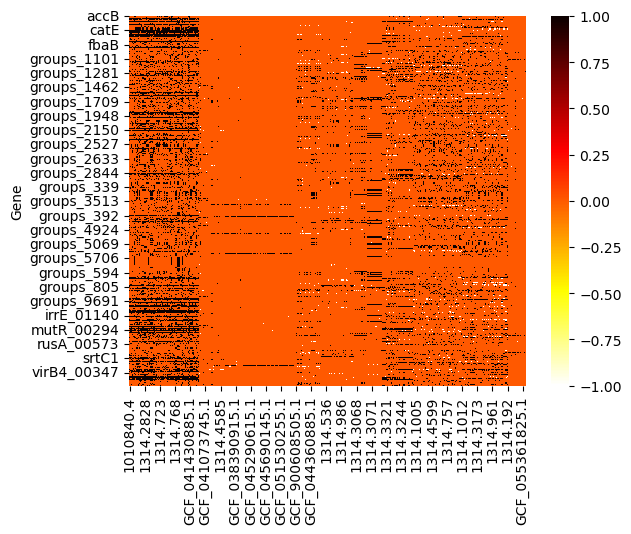

In [45]:
sns.heatmap(
    (df_acc_panta_cdhit - P_recon)[g.data2d.columns],
    cmap='hot_r'
)

In [46]:
df_acc_panta_cdhit

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
Gene,,,,,,,,,,,,,,,,,,,,,
groups_1174,1,0,0,0,0,1,0,1,0,0,...,0,0,1,1,0,1,0,0,1,0
yomH_00305,0,0,1,1,0,1,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1
groups_1627,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
rsuA_00727,1,1,0,0,1,1,0,1,0,0,...,1,1,1,0,1,0,1,0,0,0
groups_737,0,0,0,0,0,1,0,1,0,0,...,0,0,1,1,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lolD,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
groups_3403,0,1,0,0,1,0,0,0,0,0,...,0,1,1,0,0,0,1,0,0,0
groups_447,1,1,0,0,1,1,1,0,1,1,...,1,1,1,0,1,1,1,1,1,0


# Isolation Country

In [50]:
metadata.geographic_location.value_counts()

geographic_location
Iceland                       49
Italy:Varese                  31
USA                           28
Australia                     21
USA:Houston                   17
                              ..
Belgium                        1
USA: Florida                   1
USA:Virginia                   1
United Kingdom: Shrewsbury     1
USA: Texas (State)             1
Name: count, Length: 90, dtype: int64

In [51]:
metadata.isolation_country.value_counts()

isolation_country
USA                    64
Australia              24
United Kingdom         18
Fiji                    9
India                   9
Japan                   9
France                  8
Finland                 8
Brazil                  7
China                   5
Canada                  5
New Zealand             4
Iceland                 4
Kenya                   3
Russia                  2
Taiwan                  1
Hong Kong               1
Italy                   1
Saudi Arabia            1
Trinidad and Tobago     1
Ethiopia                1
Israel                  1
Netherlands             1
Name: count, dtype: int64

In [52]:
import pandas as pd
import pycountry
import plotly.express as px

# Read the metadata CSV
df = metadata.copy(deep=True)

# Function to extract the country from metadata
def extract_country(row):
    # Primary: isolation_country
    if pd.notnull(row.get('isolation_country')) and row['isolation_country'].strip():
        return row['isolation_country'].strip()
    # Fallback: geographic_location up to first ':' or ','
    geo = row.get('geographic_location', '')
    if pd.notnull(geo) and geo.strip():
        for sep in [':', ',']:
            if sep in geo:
                return geo.split(sep)[0].strip()
        return geo.strip()
    return None

# Apply extraction
df['country'] = df.apply(extract_country, axis=1)

# Count number of strains per country
counts = df['country'].value_counts().reset_index()
counts.columns = ['country', 'count']

# Map country names to ISO Alpha-3 codes
def country_to_iso3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except Exception:
        return None

counts['iso_alpha'] = counts['country'].apply(lambda x: country_to_iso3(x) if pd.notnull(x) else None)

# Remove entries without valid ISO code
counts = counts.dropna(subset=['iso_alpha'])

# Create a choropleth map
fig = px.choropleth(
    counts,
    locations='iso_alpha',
    color='count',
    hover_name='country',
    color_continuous_scale='Viridis',
    projection='natural earth',
    title='Distribution of S. aureus Strains by Country'
)

# Show the figure
fig.show()


ModuleNotFoundError: No module named 'pycountry'

In [ ]:
fig.write_image('s_aurues_country.pdf')

In [ ]:
import pandas as pd
import pycountry
import plotly.express as px

# Load metadata
df = metadata.copy(deep=True)

# Extract country function
def extract_country(row):
    if pd.notnull(row.get('isolation_country')) and row['isolation_country'].strip():
        return row['isolation_country'].strip()
    geo = row.get('geographic_location', '')
    if pd.notnull(geo) and geo.strip():
        for sep in [':', ',']:
            if sep in geo:
                return geo.split(sep)[0].strip()
        return geo.strip()
    return None

# Apply extraction
df['country'] = df.apply(extract_country, axis=1)

# Count strains per country
counts = df['country'].value_counts().reset_index()
counts.columns = ['country', 'count']

# Group small counts under 'Other'
threshold = 25
counts['country_grouped'] = counts['country'].where(counts['count'] >= threshold, 'Other')
agg = counts.groupby('country_grouped', as_index=False)['count'].sum()

# Plot pie chart
fig = px.pie(
    agg,
    names='country_grouped',
    values='count',
    title=f'S. aureus Strains by Country (Countries < {threshold} grouped as Other)',
    hole=0.3,
    color_discrete_sequence=px.colors.qualitative.G10
)
fig.show()


In [ ]:
fig.write_image('S_pyogenes_country_pie.pdf')

# Save L and A matrices

In [53]:
L_NORM_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/characterized/L_norm_panta_cdhit.csv'
A_NORM_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/characterized/A_norm_panta_cdhit.csv'

L_BIN_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/characterized/L_binarized_panta_cdhit.csv'
A_BIN_PANTA_CDHIT = '/mnt/craig/pan_phylon/S_pyogenes/processed/nmf-outputs/characterized/A_binarized_panta_cdhit.csv'

In [ ]:
# Normalized matrices
L_norm_panta_cdhit.to_csv(L_NORM_PANTA_CDHIT)
A_norm_panta_cdhit.to_csv(A_NORM_PANTA_CDHIT)

# Binarized matrices
L_binarized_panta_cdhit.to_csv(L_BIN_PANTA_CDHIT)
A_binarized_panta_cdhit.to_csv(A_BIN_PANTA_CDHIT)